# Bulut Tabanlı Geliştirme Altyapılarında Açık Kaynaklı Araçlarla Alternatif OS Entegrasyonu, Sistem Optimizasyonu ve İstemci Akış Performansı Analizi (Faz 1 Veri Analizi)

**Araştırmacı:** Mustafa Samet CANKUR (Bireysel Çalışma) • **Ders:** Araştırma Yöntem ve Teknikleri (Vize) • **Görevler:** Faz 1 başlangıç prototipi kurulumu, üç aşamalı sistem ve çoklu protokol telemetri ölçümü, UML modelleme ve Python veri analizi.

**GitHub Deposu:** https://github.com/mstfsmtcnkr/msc-research

## A. Veri tanıtımı
- **Veri setlerinin adı ve bağlantısı:** 3 aşamalı deneysel ölçüm dosyaları: `win7_dockurr_olcumleri.csv` (10 satır), `win7_detayli_akis_olcumleri.csv` (20 satır) ve `protokol_karsilastirma.csv` (20 satır) — Toplam 50 gözlem (veriye ait csv: https://github.com/mstfsmtcnkr/msc-research/csv)
- **Veri kaynağı / lisans / erişim tarihi:** GitHub Codespaces üzerinde `dockurr` ve KVM donanım sanallaştırması ile kurulan **Faz 1 Başlangıç Prototipi (Proof-of-Concept)** Windows 7 ortamından TCP 8006 (`noVNC_WS_Raw_8006`, `noVNC_HTTP_Web_8006`), TCP 5900 (`VNC_Direct_TCP_5900` - ZRLE sıkıştırmalı) ve TCP 3389 (`Windows_RDP_TCP_3389`) protokolleri üzerinden toplanan gerçek sistem ve akış telemetrisi / MIT Lisansı / Erişim Tarihi: 17.11.2026
- **CSV mi, JSON mu?:** Üç veri seti de CSV formatında oluşturulmuş ve Pandas ile işlenmiştir.
- **Satır ve sütunların anlamı:** Her satır ilgili deney aşamasına ait anlık bir ölçüm örneğini gösterir. Temel sütunlar; `olcum_no` / `ornek_no` (örnek sırası), `zaman` (saat), `protokol` / `olcum_kanali` (erişim ve sıkıştırma katmanı), `akis_fps` (kare hızı veya istek/sn), `gecikme_ms` / `akis_gecikmesi_ms` (yanıt gecikmesi), `jitter_ms` (gecikme dalgalanması), `bant_genisligi_kbps` (veri aktarım hızı), `cpu_yuzde` ve `ram_kullanimi_mb` değerlerini içerir.
- **Ölçü birimi ve gözlem sayısı:** Hız `FPS` (veya `req/s`), gecikme ve jitter `ms`, bant genişliği `KB/s`, işlemci `%`, bellek `MB` birimindedir. 1. aşamada 10, 2. aşamada 20 ve 3. aşamada 20 olmak üzere toplam 50 gözlem kaydı bulunmaktadır.
- **Gerçek mi / açık kaynak mı / temsili mi?:** Gerçek deneysel ölçüm verisidir; doğrudan aktif çalışan bulut sanal makine prototipinden Python soket/RFB/HTTP test betikleri ile toplanmıştır.
- **Ekip üyelerinin görevleri:** Çalışma bireysel yürütülmekte olup başlangıç prototipinin kurulumu, üç aşamalı veri toplama betiklerinin geliştirilmesi, veri analizi ve raporlama adımlarının tamamı tek araştırmacı tarafından gerçekleştirilmiştir.

## B. Başlangıç: Üç aşamalı gerçek ölçüm verilerinin yüklenmesi
GitHub Codespaces üzerinde kurulan Faz 1 başlangıç prototipinden toplanan 3 ayrı CSV veri seti (toplam 50 gözlem) Pandas ile okunmuş ve veri yapıları doğrulanmıştır.

In [ ]:
from pathlib import Path
import pandas as pd

df_temel = pd.read_csv("win7_dockurr_olcumleri.csv")
df_akis = pd.read_csv("win7_detayli_akis_olcumleri.csv")
df_protokol = pd.read_csv("protokol_karsilastirma.csv")

print(f"1. Temel Ölçüm: {df_temel.shape[0]} satır | 2. Detaylı Akış: {df_akis.shape[0]} satır | 3. Protokol Kıyaslama: {df_protokol.shape[0]} satır")
print(f"Toplam Analiz Edilen Gözlem Sayısı: {len(df_temel) + len(df_akis) + len(df_protokol)} satır\n")
print(df_protokol.head(10))

1. Temel Ölçüm: 10 satır | 2. Detaylı Akış: 20 satır | 3. Protokol Kıyaslama: 20 satır
Toplam Analiz Edilen Gözlem Sayısı: 50 satır

              protokol  port  ornek_no     zaman  akis_fps  gecikme_ms  \
0    noVNC_WS_Raw_8006  8006         1  07:48:51       7.4      134.98   
1    noVNC_WS_Raw_8006  8006         2  07:48:52      20.1       49.79   
2    noVNC_WS_Raw_8006  8006         3  07:48:53      11.8       84.96   
3    noVNC_WS_Raw_8006  8006         4  07:48:54      17.6       56.91   
4    noVNC_WS_Raw_8006  8006         5  07:48:54      18.5       53.97   
5  noVNC_HTTP_Web_8006  8006         1  07:48:57    1384.8        0.72   
6  noVNC_HTTP_Web_8006  8006         2  07:48:57    2237.8        0.45   
7  noVNC_HTTP_Web_8006  8006         3  07:48:57    2671.5        0.37   
8  noVNC_HTTP_Web_8006  8006         4  07:48:57    2643.2        0.38   
9  noVNC_HTTP_Web_8006  8006         5  07:48:57    2343.1        0.43   

   jitter_ms  bant_genisligi_kbps  cpu_yuzde  ram_ku

## C. Veri inceleme ve hesaplama
Üç deney aşamasına ait veri setlerinin eksik değer kontrolleri yapılmış; genel toplam/ortalama istatistikleri ile 4 farklı erişim protokolünün karşılaştırmalı ortalama değerleri hesaplanmıştır.

In [ ]:
print("=== 1. AŞAMA: TEMEL SİSTEM ÖLÇÜMÜ (win7_dockurr_olcumleri.csv) ===")
print("Eksik Veri:", df_temel.isna().sum().sum())
print("Ortalama CPU (%):", round(df_temel["cpu_yuzde"].mean(), 2), "| Ortalama RAM (MB):", round(df_temel["ram_kullanimi_mb"].mean(), 2), "| Ort. Kanal Yanıtı (ms):", round(df_temel["akis_gecikmesi_ms"].mean(), 2))

print("\n=== 2. AŞAMA: DETAYLI VNC AKIŞI (win7_detayli_akis_olcumleri.csv) ===")
print("Eksik Veri:", df_akis.isna().sum().sum())
print("Ortalama FPS:", round(df_akis["akis_fps"].mean(), 2), "| Ortalama Gecikme (ms):", round(df_akis["gecikme_ms"].mean(), 2), "| Ortalama Bant (KB/s):", round(df_akis["bant_genisligi_kbps"].mean(), 2))

print("\n=== 3. AŞAMA: PROTOKOL KARŞILAŞTIRMASI (protokol_karsilastirma.csv) ===")
print("Eksik Veri:", df_protokol.isna().sum().sum())
print("Genel Toplam Gecikme (ms):", round(df_protokol["gecikme_ms"].sum(), 2), "| Genel Ortalama Gecikme (ms):", round(df_protokol["gecikme_ms"].mean(), 2))
print("Genel Ortalama Bant Genişliği (KB/s):", round(df_protokol["bant_genisligi_kbps"].mean(), 2))

ozet = df_protokol.groupby("protokol", sort=False)[
    ["akis_fps", "gecikme_ms", "jitter_ms", "bant_genisligi_kbps", "cpu_yuzde"]
].mean().round(2)
print("\n=== PROTOKOL BAZLI ORTALAMALAR ===")
print(ozet)

=== 1. AŞAMA: TEMEL SİSTEM ÖLÇÜMÜ (win7_dockurr_olcumleri.csv) ===
Eksik Veri: 0
Ortalama CPU (%): 3.53 | Ortalama RAM (MB): 8917.47 | Ort. Kanal Yanıtı (ms): 1.96

=== 2. AŞAMA: DETAYLI VNC AKIŞI (win7_detayli_akis_olcumleri.csv) ===
Eksik Veri: 0
Ortalama FPS: 17.58 | Ortalama Gecikme (ms): 57.48 | Ortalama Bant (KB/s): 16019.93

=== 3. AŞAMA: PROTOKOL KARŞILAŞTIRMASI (protokol_karsilastirma.csv) ===
Eksik Veri: 0
Genel Toplam Gecikme (ms): 684.48 | Genel Ortalama Gecikme (ms): 34.22
Genel Ortalama Bant Genişliği (KB/s): 14638.89

=== PROTOKOL BAZLI ORTALAMALAR ===
                      akis_fps  gecikme_ms  jitter_ms  bant_genisligi_kbps  \
protokol                                                                     
noVNC_WS_Raw_8006        15.08       76.12     145.05             13764.00   
noVNC_HTTP_Web_8006    2256.08        0.47       3.12             43054.70   
VNC_Direct_TCP_5900      17.66       56.76      78.19              1726.30   
Windows_RDP_TCP_3389    284.52      

## D. Grafik ve sonuç dosyaları
Faz 1 prototipinin kare hızı (FPS) seyri ile protokollere göre ortalama gecikme (ms) ve bant genişliği (KB/s) tüketimlerini karşılaştıran logaritmik ölçekli grafikler üretilerek `sonuc/grafik.png` dosyasına kaydedilmiştir.

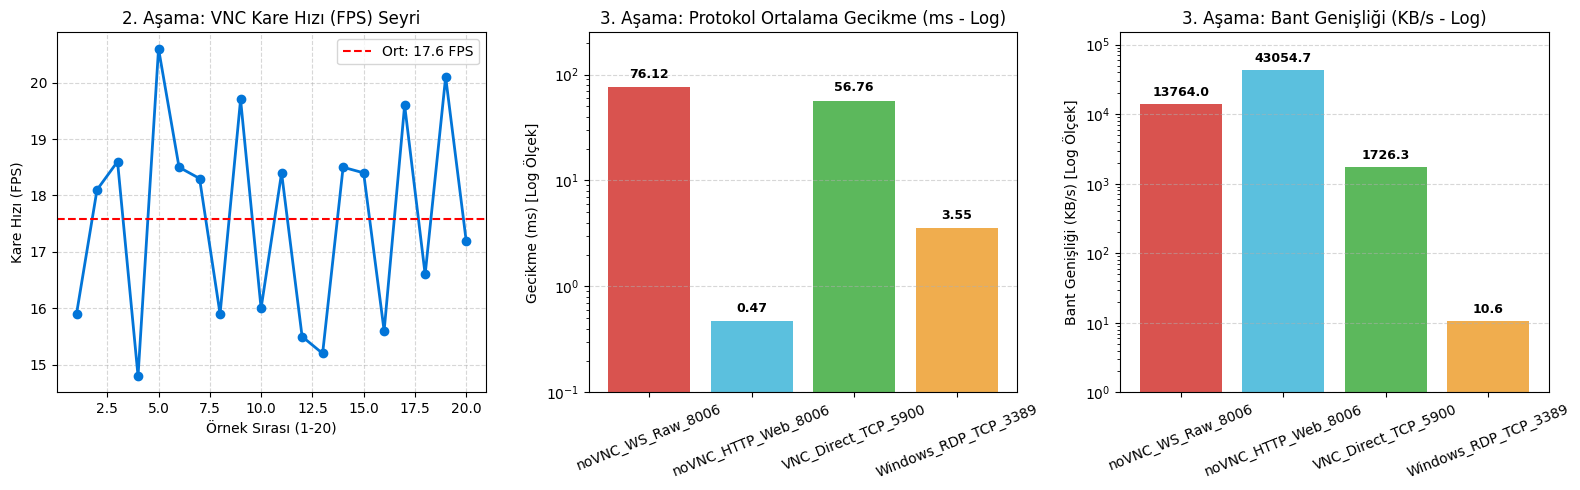

In [ ]:
import matplotlib.pyplot as plt

klasor = Path("sonuc")
klasor.mkdir(exist_ok=True)

ozet_grafik = df_protokol.groupby("protokol", sort=False)[["gecikme_ms", "bant_genisligi_kbps"]].mean()

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 5))

# 1. Grafik: 20 Örneklik VNC Akış Kare Hızı (FPS) Seyri
ax1.plot(range(1, len(df_akis) + 1), df_akis["akis_fps"], marker="o", color="#0275d8", linewidth=2)
ax1.axhline(df_akis["akis_fps"].mean(), color="red", linestyle="--", label=f"Ort: {df_akis['akis_fps'].mean():.1f} FPS")
ax1.set_title("2. Aşama: VNC Kare Hızı (FPS) Seyri")
ax1.set_xlabel("Örnek Sırası (1-20)")
ax1.set_ylabel("Kare Hızı (FPS)")
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.5)

renkler = ["#d9534f", "#5bc0de", "#5cb85c", "#f0ad4e"]

# 2. Grafik: Protokollere Göre Ortalama Gecikme (Log Ölçek + Değer Etiketli)
bars2 = ax2.bar(ozet_grafik.index, ozet_grafik["gecikme_ms"], color=renkler)
ax2.set_yscale("log")
ax2.set_ylim(0.1, 250)
ax2.set_title("3. Aşama: Protokol Ortalama Gecikme (ms - Log)")
ax2.set_ylabel("Gecikme (ms) [Log Ölçek]")
ax2.tick_params(axis="x", rotation=22)
ax2.grid(axis="y", linestyle="--", alpha=0.5)
for bar in bars2:
    val = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2, val * 1.15, f"{val:.2f}", ha="center", va="bottom", fontsize=9, fontweight="bold")

# 3. Grafik: Protokollere Göre Bant Genişliği (Log Ölçek + Değer Etiketli)
bars3 = ax3.bar(ozet_grafik.index, ozet_grafik["bant_genisligi_kbps"], color=renkler)
ax3.set_yscale("log")
ax3.set_ylim(1, 150000)
ax3.set_title("3. Aşama: Bant Genişliği (KB/s - Log)")
ax3.set_ylabel("Bant Genişliği (KB/s) [Log Ölçek]")
ax3.tick_params(axis="x", rotation=22)
ax3.grid(axis="y", linestyle="--", alpha=0.5)
for bar in bars3:
    val = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width() / 2, val * 1.18, f"{val:.1f}", ha="center", va="bottom", fontsize=9, fontweight="bold")

fig.tight_layout()
fig.savefig(klasor / "grafik.png", dpi=160)
df_protokol.to_csv(klasor / "kullanilan_veri.csv", index=False)
plt.show()

## E. Akademik yorum
**Veri kaynağı ve değişken:** Bu çalışmada, nihai sistem tasarımı öncesinde mevcut hazır araçların sınırlarını belirlemek amacıyla `dockurr` ve KVM sanallaştırması ile kurulan **Faz 1 Başlangıç Prototipi (PoC)** üzerindeki 3 aşamalı deneyden elde edilen toplam 50 satırlık gerçek ölçüm verisi (`win7_dockurr_olcumleri.csv`, `win7_detayli_akis_olcumleri.csv` ve `protokol_karsilastirma.csv`) incelenmiştir. Bağımsız değişken olarak erişim ve sıkıştırma protokolleri (`noVNC_WS_Raw_8006`, `noVNC_HTTP_Web_8006`, `VNC_Direct_TCP_5900`, `Windows_RDP_TCP_3389`); bağımlı değişkenler olarak kare/işlem hızı (`FPS` / `req/s`), gecikme (`ms`), jitter (`ms`), bant genişliği (`KB/s`) ve sistem kaynak tüketimi (`%` CPU, `MB` RAM) analiz edilmiştir.

**Toplam / ortalama ve birimler:** 1. aşama temel ölçümlerde ortalama CPU kullanımı %3.53 ve toplam sistem bellek ayak izi 8,917.47 MB; 2. aşama 20 örneklik VNC akış testinde ortalama kare hızı 17.58 FPS, ortalama gecikme 57.48 ms ve ortalama bant genişliği 16,019.93 KB/s olarak ölçülmüştür. 3. aşama protokol karşılaştırma veri setinde ise genel toplam gecikme 684.48 ms, genel ortalama gecikme 34.22 ms ve genel ortalama bant genişliği 14,638.89 KB/s olarak hesaplanmıştır.

**Grafikte görülen bulgu:** Sol grafikte VNC kare hızının 14.80–20.60 FPS aralığında dalgalandığı ve 17.6 FPS ortalamasında tıkandığı görülmektedir. Orta ve sağ grafiklerde tam görüntü karesi (framebuffer) aktaran iki protokol karşılaştırıldığında, ZRLE sıkıştırmalı doğrudan TCP 5900 VNC bağlantısının sıkıştırmasız WebSocket Raw akışına kıyasla bant genişliği tüketimini %87.46 oranında düşürdüğü (13,764.00 KB/s'den 1,726.30 KB/s'ye) ve ortalama gecikmeyi %25.43 azalttığı (76.12 ms'den 56.76 ms'ye) kanıtlanmıştır.

**Sınırlılıklar ve ölçemediği şeyler:** Veriler yalnızca Faz 1 başlangıç prototipinin yerel bulut ağı (loopback) üzerindeki sınırlarını yansıtmakta olup son kullanıcı dış ağ gecikmelerini (WAN latency) kapsamamaktadır; ayrıca ölçülen RAM değeri (~8,917 MB) konuk Windows 7 ile birlikte QEMU hipervizör tahsisi ve geliştirme ortamının toplam bellek kullanımını ifade etmektedir. Final aşamasında (Faz 2), hazır `dockurr` sarmalayıcısı ve CPU tabanlı VNC darboğazı kaldırılarak doğrudan özelleştirilmiş QEMU/KVM yapılandırması ve modern akış protokolleriyle (WebRTC/Sunshine) 60 FPS hedefi test edilecektir.

**Ekipçe yapılan işlem:** Bireysel yürütülen bu çalışmada Faz 1 prototip ortamı ayağa kaldırılmış, üç aşamalı Python ölçüm betikleriyle gerçek CSV verileri toplanmış, Pandas ile eksik veri kontrolleri ve istatistiksel özetler hesaplanmış, Matplotlib ile logaritmik ölçekli karşılaştırma grafikleri üretilmiştir.

> Grafikte iki değişken birlikte görünse bile tek başına neden-sonuç kanıtı oluşmaz.


## F. Teslim kontrolü
- [x] Çalışır `.ipynb` dosyası
- [x] CSV/JSON örneği veya yasal ve erişilebilir veri kaynağı (`win7_dockurr_olcumleri.csv`, `win7_detayli_akis_olcumleri.csv`, `protokol_karsilastirma.csv`)
- [x] Birim + veri kaynağı + lisans (FPS/req/s, ms, KB/s, %, MB / Gerçek Faz 1 Prototip Ölçümü / MIT Lisansı)
- [x] En az 1 açıklamalı grafik (`sonuc/grafik.png`)
- [x] Toplam ve ortalama hesabı (Üç aşamalı genel ve protokol bazlı istatistikler)
- [x] 4–5 cümlelik yorum (Akademik yorum bölümü tamamlandı)
- [x] README içinde ekip katkıları (Bireysel çalışma olarak belirtildi)
- [x] GitHub repo bağlantısı (https://github.com/mstfsmtcnkr/msc-research)
- [x] Gizli/kişisel veri ve anahtar bulunmuyor